**Submitted by:** Ansh Upadhyay

# Lab: From Text to BERT

## Setup

In [1]:
import math
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers
from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


# Part A: Subword tokenization

## Exercise 1: Apply BPE merges

In [2]:
def bpe_tokenize_word(word, merges, base_vocab):
    # Step 1: split the word into letters (unknown letters become [UNK])
    tokens = []
    for ch in word:
        if ch in base_vocab:
            tokens.append(ch)
        else:
            tokens.append("[UNK]")

    # Step 2: apply each merge rule in order: join every pair (a, b) into one token
    for (a, b), merged in merges:
        new_tokens = []
        i = 0
        while i < len(tokens):
            if i + 1 < len(tokens) and tokens[i] == a and tokens[i + 1] == b:
                new_tokens.append(merged)
                i = i + 2
            else:
                new_tokens.append(tokens[i])
                i = i + 1
        tokens = new_tokens

    return tokens


merges = [(("u", "g"), "ug"), (("u", "n"), "un"), (("h", "ug"), "hug")]
base_vocab = set("bghnpsu")

for word in ["hugs", "bug", "pun", "mug", "thug", "unhug"]:
    print(word, "->", bpe_tokenize_word(word, merges, base_vocab))

hugs -> ['hug', 's']
bug -> ['b', 'ug']
pun -> ['p', 'un']
mug -> ['[UNK]', 'ug']
thug -> ['[UNK]', 'hug']
unhug -> ['un', 'hug']


In [3]:
expected = {"hugs": ["hug", "s"], "bug": ["b", "ug"], "pun": ["p", "un"],
            "mug": ["[UNK]", "ug"], "thug": ["[UNK]", "hug"], "unhug": ["un", "hug"]}
for word in expected:
    assert bpe_tokenize_word(word, merges, base_vocab) == expected[word]
print("Exercise 1 checks passed.")

Exercise 1 checks passed.


**Question 1. If `(h, u) → hu` came before `(u, g) → ug`, how would `hug` be tokenized? Why must merges be applied in learned order rather than longest-first?**

`hug` becomes `['hu', 'g']`. The first rule uses up the `u`, so `u + g → ug` cannot fire, and `h + ug → hug` never gets an `ug` to work with.

Each merge was learned on top of the earlier ones: `hug` exists only because `ug` was created first. Applying the rules in another order, such as longest-first, can give splits that training never produced. The learned order reproduces the same splits the vocabulary was built from.

## Exercise 2: WordPiece longest match

In [4]:
def wordpiece_tokenize_word(word, vocab):
    tokens = []
    start = 0
    while start < len(word):
        found = None
        # try the longest piece first, then make it shorter
        for end in range(len(word), start, -1):
            piece = word[start:end]
            if start > 0:
                piece = "##" + piece          # pieces inside a word start with ##
            if piece in vocab:
                found = piece
                break
        if found is None:                     # nothing matched: whole word is unknown
            return ["[UNK]"]
        tokens.append(found)
        start = end                           # continue after the matched piece
    return tokens


vocab = {"[UNK]", "b", "h", "p", "u", "##u", "##g", "##n", "##s", "hu", "hug", "##gs", "##un"}

for word in ["hugs", "bun", "pugs", "hu", "mug", "hugsx"]:
    print(word, "->", wordpiece_tokenize_word(word, vocab))

hugs -> ['hug', '##s']
bun -> ['b', '##un']
pugs -> ['p', '##u', '##gs']
hu -> ['hu']
mug -> ['[UNK]']
hugsx -> ['[UNK]']


In [5]:
expected = {"hugs": ["hug", "##s"], "bun": ["b", "##un"], "pugs": ["p", "##u", "##gs"],
            "hu": ["hu"], "mug": ["[UNK]"], "hugsx": ["[UNK]"]}
for word in expected:
    assert wordpiece_tokenize_word(word, vocab) == expected[word]
print("Exercise 2 checks passed.")

Exercise 2 checks passed.


**Question 2. BPE gave `['[UNK]', 'ug']` for `mug` and WordPiece gave `['[UNK]']`. Give one advantage of each. Why does GPT-2's byte-level BPE never need `[UNK]`?**

- **BPE:** keeps the known part of the word (`ug`), so less information is lost.
- **WordPiece:** gives one clear "unknown word" token instead of odd fragments, and the sequence stays short.
- **GPT-2:** its base vocabulary contains all 256 possible bytes. Any text is a list of UTF-8 bytes, so every input can be written with known tokens.

## Exercise 3: How vocabulary size changes sequence length

In [6]:
# Load WikiText-2 and keep only real paragraphs (no empty lines, no "= Heading =" lines)
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

def clean(lines):
    result = []
    for line in lines:
        line = line.strip()
        if line != "" and not line.startswith("="):
            result.append(line)
    return result

train_texts = clean(wiki["train"]["text"])
val_texts = clean(wiki["validation"]["text"])


def train_tokenizer(kind, vocab_size):
    if kind == "bpe":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    else:
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    tok.normalizer = normalizers.Lowercase()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(train_texts, trainer=trainer)    # train on training text only
    return tok


def subword_stats(tokenizer, texts):
    n_words = 0
    n_tokens = 0
    n_split = 0
    n_unk = 0
    for enc in tokenizer.encode_batch(texts):
        # count how many tokens each word was split into
        count = {}
        for word_id in enc.word_ids:
            if word_id is not None:
                count[word_id] = count.get(word_id, 0) + 1

        for c in count.values():
            n_words += 1
            n_tokens += c
            if c > 1:
                n_split += 1
        n_unk += enc.tokens.count("[UNK]")

    return {"fertility": n_tokens / n_words,
            "split_rate": n_split / n_words,
            "unk_rate": n_unk / n_tokens}


fertility = {}
trained = {}
for kind in ["bpe", "wordpiece"]:
    for size in [1000, 4000, 16000]:
        tok = train_tokenizer(kind, size)
        stats = subword_stats(tok, val_texts)                 # measure on validation text
        fertility[(kind, size)] = stats["fertility"]
        trained[(kind, size)] = tok
        print(kind, size, "fertility =", round(stats["fertility"], 3),
              "split_rate =", round(stats["split_rate"], 3),
              "unk_rate =", round(stats["unk_rate"], 4))

for word in ["photosynthesis", "unbelievably", "bennett", "transformers", "kaggle"]:
    print(word)
    for kind in ["bpe", "wordpiece"]:
        for size in [1000, 16000]:
            print("   ", kind, size, trained[(kind, size)].encode(word).tokens)

bpe 1000 fertility = 2.861 split_rate = 0.601 unk_rate = 0.0003


bpe 4000 fertility = 1.407 split_rate = 0.258 unk_rate = 0.0005


bpe 16000 fertility = 1.129 split_rate = 0.092 unk_rate = 0.0007


wordpiece 1000 fertility = 4.3 split_rate = 0.835 unk_rate = 0.0001


wordpiece 4000 fertility = 1.526 split_rate = 0.309 unk_rate = 0.0002


wordpiece 16000 fertility = 1.151 split_rate = 0.102 unk_rate = 0.0003
photosynthesis
    bpe 1000 ['p', 'h', 'o', 'to', 's', 'y', 'n', 'the', 's', 'is']
    bpe 16000 ['photo', 'synthesis']
    wordpiece 1000 ['p', '##h', '##o', '##t', '##o', '##s', '##y', '##n', '##t', '##h', '##e', '##s', '##i', '##s']
    wordpiece 16000 ['photos', '##yn', '##the', '##sis']
unbelievably
    bpe 1000 ['un', 'b', 'el', 'i', 'e', 'v', 'a', 'b', 'ly']
    bpe 16000 ['un', 'belie', 'v', 'ably']
    wordpiece 1000 ['u', '##n', '##b', '##e', '##l', '##i', '##e', '##v', '##a', '##b', '##l', '##y']
    wordpiece 16000 ['un', '##bel', '##ie', '##va', '##bl', '##y']
bennett
    bpe 1000 ['b', 'en', 'n', 'e', 't', 't']
    bpe 16000 ['bennett']
    wordpiece 1000 ['b', '##e', '##n', '##n', '##e', '##t', '##t']
    wordpiece 16000 ['bennett']
transformers
    bpe 1000 ['t', 'r', 'an', 's', 'for', 'm', 'er', 's']
    bpe 16000 ['trans', 'form', 'ers']
    wordpiece 1000 ['t', '##r', '##a', '##n', '##s', '##f', '

In [7]:
result = subword_stats(tok, ["tokenization is useful"])
assert set(result) == {"fertility", "split_rate", "unk_rate"}
assert result["fertility"] >= 1.0 and 0.0 <= result["split_rate"] <= 1.0
assert abs(result["fertility"] - len(tok.encode("tokenization is useful").tokens) / 3) < 1e-9
print("Exercise 3 checks passed.")

Exercise 3 checks passed.


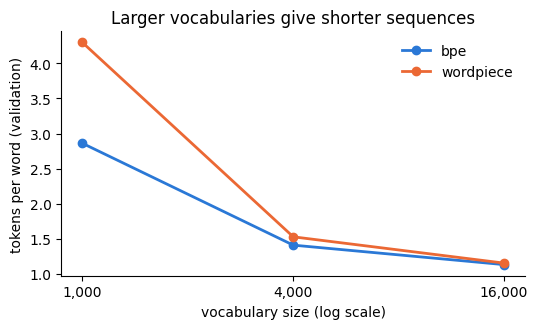

In [8]:
sizes = [1000, 4000, 16000]
colors = {"bpe": "#2a78d6", "wordpiece": "#eb6834"}

plt.figure(figsize=(5.5, 3.4))
for kind in ["bpe", "wordpiece"]:
    values = [fertility[(kind, size)] for size in sizes]
    plt.plot(sizes, values, marker="o", linewidth=2, color=colors[kind], label=kind)
plt.xscale("log")
plt.xticks(sizes, ["1,000", "4,000", "16,000"])
plt.minorticks_off()
plt.xlabel("vocabulary size (log scale)")
plt.ylabel("tokens per word (validation)")
plt.title("Larger vocabularies give shorter sequences")
plt.legend(frameon=False)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Question 3. (a) What is the trend in fertility as the vocabulary grows? (b) How many embedding parameters do 16,000 and 1,000 tokens need when d = 768? (c) What is the trade-off, and why measure on validation paragraphs?**

**(a)** Fertility falls as the vocabulary grows, quickly at first and then more slowly.

| Vocabulary size | BPE | WordPiece |
| --- | --- | --- |
| 1,000 | 2.861 | 4.300 |
| 4,000 | 1.407 | 1.526 |
| 16,000 | 1.129 | 1.151 |

WordPiece needs more tokens than BPE at every size, and the gap is largest at 1,000. For example, `photosynthesis` takes 14 WordPiece tokens at 1,000 but only 2 BPE tokens at 16,000 (`photo`, `synthesis`).

**(b)** Parameters = vocabulary size × d.
- 16,000 × 768 = **12,288,000**
- 1,000 × 768 = **768,000**

The larger vocabulary needs 16 times as many parameters, which is 11,520,000 more.

**(c)** A larger vocabulary gives shorter sequences, so attention is cheaper and more text fits in the context window. The cost is a larger embedding table, and rare tokens get few training examples. A smaller vocabulary has the opposite effect. Going from 4,000 to 16,000 costs 4 times the parameters but cuts BPE fertility only from 1.407 to 1.129, so each extra token helps less.

The tokenizers were trained on the training paragraphs, so measuring there would look too good. Validation paragraphs show how they behave on new text.

## Exercise 4: One sentence, three tokenizers, three languages

In [9]:
def tokens_per_word(tokenizer, text):
    n_tokens = len(tokenizer.tokenize(text))
    n_words = len(text.split())
    return n_tokens / n_words


names = ["google-bert/bert-base-uncased",
         "google-bert/bert-base-multilingual-cased",
         "openai-community/gpt2"]

sentences = {"English":  "I like Indian food very much.",
             "Hindi":    "मुझे भारतीय खाना बहुत पसंद है।",
             "Hinglish": "Mujhe Indian khana bahut pasand hai."}

for name in names:
    tok = AutoTokenizer.from_pretrained(name)
    print(name)
    for lang, text in sentences.items():
        print("   ", lang, round(tokens_per_word(tok, text), 2), "tokens per word")
        print("       ", tok.tokenize(text))

# What does bert-base-uncased do to the Hindi sentence?
tok = AutoTokenizer.from_pretrained(names[0])
ids = tok.encode(sentences["Hindi"], add_special_tokens=False)
print("\nOriginal :", sentences["Hindi"])
print("Decoded  :", tok.decode(ids))

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


google-bert/bert-base-uncased
    English 1.17 tokens per word
        ['i', 'like', 'indian', 'food', 'very', 'much', '.']
    Hindi 3.17 tokens per word
        ['[UNK]', 'भ', '##ा', '##र', '##त', '##ी', '##य', 'ख', '##ा', '##न', '##ा', 'ब', '##ह', '##त', 'प', '##स', '##द', 'ह', '।']
    Hinglish 2.17 tokens per word
        ['mu', '##j', '##he', 'indian', 'khan', '##a', 'ba', '##hu', '##t', 'pas', '##and', 'hai', '.']


google-bert/bert-base-multilingual-cased
    English 1.17 tokens per word
        ['I', 'like', 'Indian', 'food', 'very', 'much', '.']
    Hindi 2.17 tokens per word
        ['म', '##ु', '##झ', '##े', 'भारतीय', 'खान', '##ा', 'बहुत', 'प', '##स', '##ंद', 'है', '।']
    Hinglish 2.0 tokens per word
        ['Mu', '##j', '##he', 'Indian', 'khan', '##a', 'ba', '##hut', 'pasa', '##nd', 'hai', '.']


openai-community/gpt2
    English 1.17 tokens per word
        ['I', 'Ġlike', 'ĠIndian', 'Ġfood', 'Ġvery', 'Ġmuch', '.']
    Hindi 7.83 tokens per word
        ['à¤', '®', 'à¥', 'ģ', 'à¤', 'Ŀ', 'à¥', 'ĩ', 'Ġà¤', 'Ń', 'à¤¾', 'à¤', '°', 'à¤', '¤', 'à¥', 'Ģ', 'à¤', '¯', 'Ġà¤', 'ĸ', 'à¤¾', 'à¤', '¨', 'à¤¾', 'Ġà¤', '¬', 'à¤', '¹', 'à¥', 'ģ', 'à¤', '¤', 'Ġà¤', 'ª', 'à¤', '¸', 'à¤', 'Ĥ', 'à¤', '¦', 'Ġà¤', '¹', 'à¥', 'Ī', 'à¥', '¤']
    Hinglish 2.33 tokens per word
        ['M', 'uj', 'he', 'ĠIndian', 'Ġkh', 'ana', 'Ġb', 'ah', 'ut', 'Ġpas', 'and', 'Ġha', 'i', '.']



Original : मुझे भारतीय खाना बहुत पसंद है।
Decoded  : [UNK] भारतीय खाना बहत पसद ह ।


In [10]:
tok = AutoTokenizer.from_pretrained(names[0])
assert abs(tokens_per_word(tok, "hello world") - len(tok.tokenize("hello world")) / 2) < 1e-9
print("Exercise 4 checks passed.")

Exercise 4 checks passed.


**Question 4. (a) Which tokenizer is most efficient for each language, and which is least efficient for Hindi? (b) What happened to the decoded Hindi from `bert-base-uncased`? (c) What does this imply for users who write in Hindi?**

**(a)** Tokens per word:

| | bert-base-uncased | bert-base-multilingual-cased | gpt2 |
| --- | --- | --- | --- |
| English | 1.17 | 1.17 | 1.17 |
| Hindi | 3.17 | **2.17** | 7.83 |
| Hinglish | 2.17 | **2.00** | 2.33 |

- **English:** all three tie at 1.17.
- **Hindi and Hinglish:** the multilingual tokenizer is best, because it was trained on Wikipedia in about 100 languages, including Hindi.
- **Least efficient for Hindi:** GPT-2 at 7.83, because it works on UTF-8 bytes and each Devanagari character takes 3 bytes.

**(b)** Information was lost, so the text cannot be recovered.
- Original: `मुझे भारतीय खाना बहुत पसंद है।`
- Decoded: `[UNK] भारतीय खाना बहत पसद ह ।`

The first word became `[UNK]`, and some vowel signs and marks disappeared (`बहुत → बहत`, `पसंद → पसद`, `है → ह`). The uncased tokenizer strips accents, and it treats these Hindi marks as accents.

**(c)** Hindi users spend more tokens on the same message. With GPT-2 it is about 6.7 times as many as English here (7.83 / 1.17). They pay more on per-token APIs and fit less text in the context window. This one short sentence is only a small sample, but the gap is large.

# Part B: Self-attention with a padding mask

## Exercises 5 and 6: Masked attention and the padding mask

In [11]:
def scaled_dot_product_attention(q, k, v, mask=None):
    d_k = q.shape[-1]
    # Step 1: how similar is each query to each key
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)
    # Step 2: blocked positions (mask == False) get -infinity
    if mask is not None:
        scores = scores.masked_fill(mask == False, float("-inf"))
    # Step 3: softmax -> weights (each row adds up to 1), then mix the values
    weights = F.softmax(scores, dim=-1)
    output = weights @ v
    return output, weights


def make_padding_mask(input_ids, pad_id):
    B, T = input_ids.shape
    mask = input_ids != pad_id            # True for real tokens, False for padding
    return mask.view(B, 1, 1, T)          # extra dims so it fits (B, H, T, T)


# Test: 2 sentences of 5 tokens, the second one ends with 2 padding tokens (id 0)
ids = torch.tensor([[5, 6, 7, 8, 9],
                    [5, 6, 7, 0, 0]])
mask = make_padding_mask(ids, pad_id=0)

q = torch.randn(2, 3, 5, 4)               # (batch, heads, tokens, d_k)
k = torch.randn(2, 3, 5, 4)
v = torch.randn(2, 3, 5, 4)

out, w = scaled_dot_product_attention(q, k, v, mask)
torch_out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)

print("output shape :", out.shape)
print("weights shape:", w.shape)
print("same as PyTorch:", torch.allclose(out, torch_out, atol=1e-5))
print("weights of sentence 2 (last 2 columns are padding):")
print(w[1, 0].round(decimals=2))

output shape : torch.Size([2, 3, 5, 4])
weights shape: torch.Size([2, 3, 5, 5])
same as PyTorch: True
weights of sentence 2 (last 2 columns are padding):
tensor([[0.3300, 0.1000, 0.5800, 0.0000, 0.0000],
        [0.1100, 0.5300, 0.3600, 0.0000, 0.0000],
        [0.2600, 0.1600, 0.5800, 0.0000, 0.0000],
        [0.3200, 0.3200, 0.3600, 0.0000, 0.0000],
        [0.5100, 0.0800, 0.4100, 0.0000, 0.0000]])


In [12]:
assert out.shape == (2, 3, 5, 4) and w.shape == (2, 3, 5, 5)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 5))               # each row of weights adds up to 1
assert (w[1, :, :, 3:] == 0).all()                                  # padding gets exactly zero weight
assert torch.allclose(out, torch_out, atol=1e-5)                    # same as PyTorch with a mask
no_mask_out, _ = scaled_dot_product_attention(q, k, v)
assert torch.allclose(no_mask_out, F.scaled_dot_product_attention(q, k, v), atol=1e-5)   # and without a mask
print("Exercise 5 checks passed.")

test_mask = make_padding_mask(torch.tensor([[5, 6, 7, 0, 0], [8, 9, 10, 11, 12]]), pad_id=0)
assert test_mask.shape == (2, 1, 1, 5) and test_mask.dtype == torch.bool
assert test_mask[0, 0, 0].tolist() == [True, True, True, False, False] and test_mask[1].all()
print("Exercise 6 checks passed.")

Exercise 5 checks passed.
Exercise 6 checks passed.


### Provided: a small Transformer encoder

In [13]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d_model, d_model) for _ in range(4))

    def forward(self, x, mask=None):                                   # x: (B, T, D)
        B, T, D = x.shape
        split = lambda t: t.view(B, T, self.h, self.d_k).transpose(1, 2)        # (B, H, T, d_k)
        out, weights = scaled_dot_product_attention(split(self.W_q(x)), split(self.W_k(x)), split(self.W_v(x)), mask)
        return self.W_o(out.transpose(1, 2).reshape(B, T, D)), weights          # merge heads -> (B, T, D)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        a, _ = self.attn(x, mask)
        x = self.norm1(x + self.drop(a))                  # residual + layer norm (post-norm, as in the paper)
        return self.norm2(x + self.drop(self.ff(x)))


class TinyEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=32, n_heads=4, d_ff=64, n_layers=2, max_len=64, pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        pos = torch.arange(max_len)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.layers = nn.ModuleList(EncoderLayer(d_model, n_heads, d_ff) for _ in range(n_layers))

    def forward(self, ids, mask=None):                   # ids: (B, T)
        x = self.emb(ids) * math.sqrt(self.emb.embedding_dim) + self.pe[: ids.size(1)]
        for layer in self.layers:
            x = layer(x, mask)
        return x                                          # (B, T, D)

## Exercise 7: Prove that padding cannot leak

In [14]:
@torch.no_grad()
def padding_leakage(model, ids, junk_ids, pad_id, use_mask=True):
    # use the SAME mask for both runs
    if use_mask:
        mask = make_padding_mask(ids, pad_id)
    else:
        mask = None

    out1 = model(ids, mask)
    out2 = model(junk_ids, mask)

    real = ids != pad_id                       # only compare the real tokens
    return (out1[real] - out2[real]).abs().max().item()


torch.manual_seed(42)
encoder = TinyEncoder(vocab_size=50).eval()

ids      = torch.tensor([[7, 8, 9, 0, 0, 0], [10, 11, 12, 13, 14, 0]])
junk_ids = torch.tensor([[7, 8, 9, 31, 32, 33], [10, 11, 12, 13, 14, 34]])   # only padding changed

print("with mask   :", padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=True))
print("without mask:", padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=False))

with mask   : 0.0


without mask: 0.7283346652984619


In [15]:
assert padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=True) < 1e-5
assert padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=False) > 1e-3
print("Exercise 7 checks passed.")

Exercise 7 checks passed.


**Question 5. (a) Give the shapes for `B = 2`, `T = 6`, `D = 32`, `H = 4`. (b) Why is it harmless for BERT that padded positions still produce outputs? (c) Why does BERT use a padding mask but no causal mask, while GPT-2 uses both?**

**(a)** Here d_k = 32 / 4 = 8.

| Tensor | Shape |
| --- | --- |
| Input IDs | `(2, 6)` |
| Embeddings | `(2, 6, 32)` |
| `q` after splitting into heads | `(2, 4, 6, 8)` |
| Attention weights | `(2, 4, 6, 6)` |
| Encoder output | `(2, 6, 32)` |

**(b)** No real token can read those outputs, because the mask hides padded keys in every layer. BERT also takes no loss or prediction at padded positions, so the vectors are simply ignored. My test supports the first part: changing only the padding changed real positions by 0.0 with the mask and by 0.73 without it.

**(c)**
- **BERT** fills in hidden words, so each token should see both sides. It only needs to ignore padding.
- **GPT-2** predicts the next word, so a causal mask stops it from seeing future tokens. It also needs a padding mask when a batch has different lengths.

# Part C: BERT inputs, objective and predictions

In [16]:
bert_tok = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
bert_mlm = AutoModelForMaskedLM.from_pretrained("google-bert/bert-base-uncased").to(device).eval()

Some weights of the model checkpoint at google-bert/bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


## Exercise 8: BERT's three input tensors

In [17]:
def describe_bert_input(enc, tokenizer):
    ids = enc["input_ids"][0].tolist()
    types = enc["token_type_ids"][0].tolist()
    attn = enc["attention_mask"][0].tolist()

    cls_position = ids.index(tokenizer.cls_token_id)
    sep_positions = [i for i in range(len(ids)) if ids[i] == tokenizer.sep_token_id]
    segment_b_tokens = sum(1 for i in range(len(ids)) if types[i] == 1 and attn[i] == 1)
    pad_tokens = attn.count(0)

    return {"cls_position": cls_position, "sep_positions": sep_positions,
            "segment_b_tokens": segment_b_tokens, "pad_tokens": pad_tokens}


pair = bert_tok("The cat sat on the mat.", "It looked very comfortable.",
                padding="max_length", max_length=20, return_tensors="pt")

tokens = bert_tok.convert_ids_to_tokens(pair["input_ids"][0])
for i in range(len(tokens)):
    print(i, tokens[i], "type =", pair["token_type_ids"][0][i].item(), "attn =", pair["attention_mask"][0][i].item())

print(describe_bert_input(pair, bert_tok))

0 [CLS] type = 0 attn = 1
1 the type = 0 attn = 1
2 cat type = 0 attn = 1
3 sat type = 0 attn = 1
4 on type = 0 attn = 1
5 the type = 0 attn = 1
6 mat type = 0 attn = 1
7 . type = 0 attn = 1
8 [SEP] type = 0 attn = 1
9 it type = 1 attn = 1
10 looked type = 1 attn = 1
11 very type = 1 attn = 1
12 comfortable type = 1 attn = 1
13 . type = 1 attn = 1
14 [SEP] type = 1 attn = 1
15 [PAD] type = 0 attn = 0
16 [PAD] type = 0 attn = 0
17 [PAD] type = 0 attn = 0
18 [PAD] type = 0 attn = 0
19 [PAD] type = 0 attn = 0
{'cls_position': 0, 'sep_positions': [8, 14], 'segment_b_tokens': 6, 'pad_tokens': 5}


In [18]:
info = describe_bert_input(pair, bert_tok)
assert info["cls_position"] == 0
assert len(info["sep_positions"]) == 2
assert info["segment_b_tokens"] == len(bert_tok.tokenize("It looked very comfortable.")) + 1   # + closing [SEP]
assert info["pad_tokens"] == 20 - (info["sep_positions"][-1] + 1)
print("Exercise 8 checks passed.")

Exercise 8 checks passed.


**Question 6. Which segment does each `[SEP]` belong to? What `token_type_ids` do padding positions get, and why does it not matter? What is `[CLS]`'s final hidden state used for in sentence-pair classification?**

- **`[SEP]`:** the first one (position 8) has type 0, so it belongs to sentence A. The second one (position 14) has type 1, so it belongs to sentence B.
- **Padding:** positions 15–19 get type 0. This does not matter because their attention mask is 0, so real tokens never read them and no loss is taken there.
- **`[CLS]`:** its final hidden state acts as a summary of the whole pair. A small classifier on top of it predicts the label.

## Exercise 9: BERT's 80/10/10 masking rule

In [19]:
def mask_tokens(input_ids, special_mask, mask_token_id, vocab_size, mlm_prob=0.15, generator=None):
    masked_ids = input_ids.clone()      # copy, so the original is not changed
    labels = input_ids.clone()
    shape = input_ids.shape

    # Step 1: choose 15% of the tokens, but never special tokens or padding
    chosen = torch.rand(shape, generator=generator) < mlm_prob
    chosen = chosen & (special_mask == False)

    # Step 2: tokens that were not chosen get label -100 (ignored by the loss)
    labels[chosen == False] = -100

    # Step 3: 80% of the chosen tokens -> [MASK]
    to_mask = chosen & (torch.rand(shape, generator=generator) < 0.8)
    masked_ids[to_mask] = mask_token_id

    # Step 4: of the other 20%, half -> random word, half stays the same
    to_random = chosen & (to_mask == False) & (torch.rand(shape, generator=generator) < 0.5)
    random_words = torch.randint(vocab_size, shape, generator=generator)
    masked_ids[to_random] = random_words[to_random]

    return masked_ids, labels


batch = bert_tok(val_texts[:512], padding=True, truncation=True, max_length=128,
                 return_tensors="pt", return_special_tokens_mask=True)
original = batch["input_ids"]
special_mask = (batch["special_tokens_mask"] == 1) | (batch["attention_mask"] == 0)

masked_ids, labels = mask_tokens(original, special_mask, bert_tok.mask_token_id,
                                 bert_tok.vocab_size, generator=torch.Generator().manual_seed(42))

# Check the percentages
chosen = labels != -100
is_mask = chosen & (masked_ids == bert_tok.mask_token_id)
is_same = chosen & (masked_ids == original)
is_random = chosen & (is_mask == False) & (is_same == False)

n_chosen = chosen.sum().item()
print("chosen   :", round(n_chosen / (special_mask == False).sum().item(), 3), "(target 0.15)")
print("[MASK]   :", round(is_mask.sum().item() / n_chosen, 3), "(target 0.8)")
print("random   :", round(is_random.sum().item() / n_chosen, 3), "(target 0.1)")
print("unchanged:", round(is_same.sum().item() / n_chosen, 3), "(target 0.1)")

chosen   : 0.148 (target 0.15)
[MASK]   : 0.792 (target 0.8)
random   : 0.105 (target 0.1)
unchanged: 0.103 (target 0.1)


In [20]:
before = original.clone()
mask_tokens(original, special_mask, bert_tok.mask_token_id, bert_tok.vocab_size,
            generator=torch.Generator().manual_seed(42))
assert torch.equal(original, before)                                 # input_ids not modified
assert not (chosen & special_mask).any()                             # no special tokens or padding chosen
assert torch.equal(labels[chosen], original[chosen])                 # labels hold the original words
assert torch.equal(masked_ids[~chosen], original[~chosen])           # other tokens did not change

eligible = (~special_mask).sum().item()
assert abs(n_chosen / eligible - 0.15) < 0.01
assert abs(is_mask.sum().item() / n_chosen - 0.8) < 0.03
assert abs(is_random.sum().item() / n_chosen - 0.1) < 0.03
assert abs(is_same.sum().item() / n_chosen - 0.1) < 0.03
print("Exercise 9 checks passed.")

Exercise 9 checks passed.


**Question 7. (a) Why not replace all selected tokens by `[MASK]`? (b) Why keep 10% unchanged and replace 10% with random tokens? (c) Why is it harmless if a random replacement picks the original token?**

**(a)** `[MASK]` never appears in normal text. If every target were `[MASK]`, the model could learn to predict only at that token and put little effort into other tokens, yet normal text is all it sees later.

**(b)**
- **Unchanged (10%):** keeps the model's outputs tied to the words actually present in the text.
- **Random (10%):** means no visible token can be fully trusted, so the model must check every word against its context.

My run was close to the target: 79.2% `[MASK]`, 10.5% random and 10.3% unchanged, with 14.8% of eligible tokens chosen.

**(c)** That position just acts as an unchanged example, and its label is still correct. It happens with probability of about 1 in 30,522, the vocabulary size, so the effect is tiny.

## Exercise 10: BERT's top-k predictions

In [21]:
@torch.no_grad()
def mask_probs(text):
    """Probability of every word in the vocabulary at the [MASK] position."""
    enc = bert_tok(text, return_tensors="pt").to(device)
    logits = bert_mlm(**enc).logits[0]                         # (tokens, vocab)
    ids = enc["input_ids"][0].tolist()
    mask_pos = ids.index(bert_tok.mask_token_id)
    return F.softmax(logits[mask_pos], dim=-1)


def top_k_predictions(text, k=5):
    probs = mask_probs(text)
    top = torch.topk(probs, k)
    words = bert_tok.convert_ids_to_tokens(top.indices.tolist())
    return [(words[i], top.values[i].item()) for i in range(k)]


sentences = ["The cat sat on the [MASK].",
             "Paris is the capital of [MASK].",
             "She opened the [MASK] and walked into the room.",
             "The doctor gave me some [MASK] for my headache.",
             "Bennett University is located in [MASK]."]
for s in sentences:
    print(s, [(word, round(p, 3)) for word, p in top_k_predictions(s)])

The cat sat on the [MASK]. [('floor', 0.314), ('bed', 0.119), ('couch', 0.107), ('sofa', 0.06), ('ground', 0.055)]
Paris is the capital of [MASK]. [('france', 0.951), ('algeria', 0.012), ('morocco', 0.003), ('reunion', 0.003), ('haiti', 0.003)]
She opened the [MASK] and walked into the room. [('door', 0.987), ('doors', 0.003), ('window', 0.001), ('curtain', 0.001), ('curtains', 0.001)]
The doctor gave me some [MASK] for my headache. [('medication', 0.274), ('medicine', 0.088), ('treatment', 0.079), ('help', 0.075), ('water', 0.072)]
Bennett University is located in [MASK]. [('bennett', 0.185), ('omaha', 0.035), ('sacramento', 0.031), ('burlington', 0.026), ('nashville', 0.023)]


In [22]:
from transformers import pipeline

preds = top_k_predictions("The cat sat on the [MASK].", k=5)
pred_probs = [p for word, p in preds]
assert len(preds) == 5 and pred_probs == sorted(pred_probs, reverse=True) and 0 < sum(pred_probs) <= 1 + 1e-6

fill = pipeline("fill-mask", model=bert_mlm, tokenizer=bert_tok, device=0 if device == "cuda" else -1)
best = fill("The cat sat on the [MASK].", top_k=1)[0]
assert bert_tok.convert_tokens_to_ids(preds[0][0]) == best["token"]
assert abs(preds[0][1] - best["score"]) < 1e-3
print("Exercise 10 checks passed.")

Exercise 10 checks passed.


### How often does BERT recover masked tokens?

In [23]:
# Run BERT on the masked batch (64 paragraphs at a time) and keep its best guess for every token
predictions = []
losses = []
with torch.no_grad():
    for start in range(0, len(masked_ids), 64):
        ids = masked_ids[start:start + 64].to(device)
        attn = batch["attention_mask"][start:start + 64].to(device)
        target = labels[start:start + 64].to(device)
        result = bert_mlm(input_ids=ids, attention_mask=attn, labels=target)
        losses.append(result.loss.item())
        predictions.append(result.logits.argmax(dim=-1).cpu())
predictions = torch.cat(predictions)

# Accuracy = how often the guess equals the original word
for name, positions in [("[MASK]", is_mask), ("random", is_random), ("unchanged", is_same)]:
    correct = (predictions[positions] == original[positions]).float().mean().item()
    print(name, "accuracy =", round(correct, 3))

print("mean MLM loss =", round(sum(losses) / len(losses), 3))

[MASK] accuracy = 0.612
random accuracy = 0.477
unchanged accuracy = 0.965
mean MLM loss = 2.153


**Question 8. Rank the three kinds of positions by accuracy and explain the ranking. Why is accuracy at `unchanged` positions not evidence that BERT understands text?**

| Rank | Position | Top-1 accuracy | Why |
| --- | --- | --- | --- |
| 1 | unchanged | 0.965 | The correct word is visible in the input. |
| 2 | `[MASK]` | 0.612 | The word is hidden, so it must come from context. |
| 3 | random | 0.477 | The input shows a wrong word, which BERT must overcome using context. |

A model that only copied its input would score 100% at `unchanged` positions while understanding nothing, so that number says little. The `[MASK]` accuracy is more meaningful, but it is probably optimistic because WikiText comes from Wikipedia, which was part of BERT's pretraining data.

**What surprised me:** for `Bennett University is located in [MASK].`, the top prediction was `bennett` (0.185), followed by US cities such as `omaha` and `sacramento`. BERT seems to guess from the name and has no real knowledge of this university, even though it answers `france` with 0.951 for the capital of France.

## Exercise 11: A careful bias probe

In [24]:
def pronoun_probs(sentence):
    probs = mask_probs(sentence)
    p_he = probs[bert_tok.convert_tokens_to_ids("he")].item()
    p_she = probs[bert_tok.convert_tokens_to_ids("she")].item()
    return p_he, p_she


occupations = ["nurse", "receptionist", "teacher", "doctor", "engineer", "pilot", "programmer", "scientist"]
templates = ["the {occ} said that [MASK] was tired.",
             "after the meeting, the {occ} explained why [MASK] had to leave early."]

for template in templates:
    print(template)
    for occ in occupations:
        p_he, p_she = pronoun_probs(template.format(occ=occ))
        print("   ", occ, " P(he) =", round(p_he, 3), " P(she) =", round(p_she, 3),
              " log(he/she) =", round(math.log(p_he / p_she), 2))

the {occ} said that [MASK] was tired.
    nurse  P(he) = 0.187  P(she) = 0.637  log(he/she) = -1.22
    receptionist  P(he) = 0.075  P(she) = 0.815  log(he/she) = -2.39
    teacher  P(he) = 0.467  P(she) = 0.377  log(he/she) = 0.21


    doctor  P(he) = 0.48  P(she) = 0.328  log(he/she) = 0.38
    engineer  P(he) = 0.82  P(she) = 0.053  log(he/she) = 2.75
    pilot  P(he) = 0.855  P(she) = 0.081  log(he/she) = 2.36
    programmer  P(he) = 0.788  P(she) = 0.111  log(he/she) = 1.96
    scientist  P(he) = 0.691  P(she) = 0.142  log(he/she) = 1.58
after the meeting, the {occ} explained why [MASK] had to leave early.
    nurse  P(he) = 0.085  P(she) = 0.355  log(he/she) = -1.42


    receptionist  P(he) = 0.102  P(she) = 0.43  log(he/she) = -1.44
    teacher  P(he) = 0.327  P(she) = 0.273  log(he/she) = 0.18
    doctor  P(he) = 0.534  P(she) = 0.081  log(he/she) = 1.89
    engineer  P(he) = 0.527  P(she) = 0.026  log(he/she) = 3.02
    pilot  P(he) = 0.423  P(she) = 0.032  log(he/she) = 2.59
    programmer  P(he) = 0.631  P(she) = 0.061  log(he/she) = 2.34
    scientist  P(he) = 0.538  P(she) = 0.073  log(he/she) = 2.0


In [25]:
p_he, p_she = pronoun_probs("Yesterday [MASK] went to the market.")
assert 0 <= p_he <= 1 and 0 <= p_she <= 1 and p_he + p_she <= 1 + 1e-6
print("Exercise 11 checks passed.")

Exercise 11 checks passed.


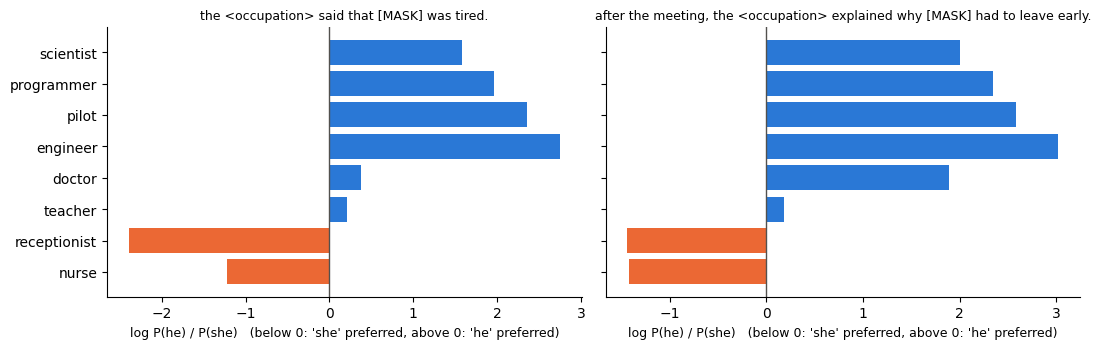

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

for ax, template in zip(axes, templates):
    log_ratios = []
    for occ in occupations:
        p_he, p_she = pronoun_probs(template.format(occ=occ))
        log_ratios.append(math.log(p_he / p_she))

    colors = ["#eb6834" if r < 0 else "#2a78d6" for r in log_ratios]
    ax.barh(occupations, log_ratios, color=colors)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_xlabel("log P(he) / P(she)   (below 0: 'she' preferred, above 0: 'he' preferred)", fontsize=9)
    ax.set_title(template.replace("{occ}", "<occupation>"), fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Question 9. (a) Summarize what the two charts show. Are the occupation rankings the same? (b) Give at least three reasons this does not establish how biased BERT is in practice. (c) Suggest one change that would make the conclusions more reliable.**

**(a)** Both templates prefer `she` for nurse and receptionist, and `he` for doctor, scientist, programmer, pilot and engineer. Teacher is nearly neutral (+0.21 and +0.18).

The ranking is the same in both, from most `she` to most `he`: receptionist, nurse, teacher, doctor, scientist, programmer, pilot, engineer.

The sizes do change. Doctor goes from +0.38 to +1.89, and receptionist from −2.39 to −1.44. P(he) + P(she) also drops: for pilot it falls from 0.936 to 0.455, so other words take much more of the probability in the second template.

**(b)**
1. **Few templates:** two hand-written sentences are a small sample, and the sizes already changed a lot between them.
2. **Narrow coverage:** there are only 8 occupations and 2 pronouns, so `they` and other kinds of bias are not tested.
3. **Different task:** filling in a blank is not what a deployed system does. A fine-tuned model may behave differently.
4. **No baseline:** we did not compare against a neutral sentence or real occupation statistics, so we cannot say how much of the gap comes from the occupation word.

**(c)** Use many more templates, written by different people, and report the average log-ratio with its spread. Include a neutral baseline such as `the person said that [MASK] was tired.`